# **Day 86: Matplotlib Basics - Drawing Charts**

**Matplotlib** is the most popular library for drawing **charts and graphs** in Python. A good chart can explain data much faster than a table of numbers.

Install it with `pip install matplotlib`. We usually import it like this:

In [1]:
import matplotlib.pyplot as plt
import numpy as np

## **Line Chart**
A **line chart** shows how something **changes over time**.

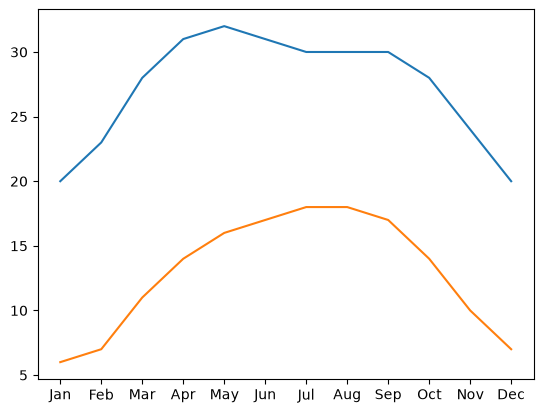

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
kolkata = [20, 23, 28, 31, 32, 31, 30, 30, 30, 28, 24, 20]       # Average temperature (approx)
darjeeling = [6, 7, 11, 14, 16, 17, 18, 18, 17, 14, 10, 7]

plt.plot(months, kolkata)
plt.plot(months, darjeeling)
plt.show()

This chart works, but it has no title, no labels and no legend. A good chart must always have these.

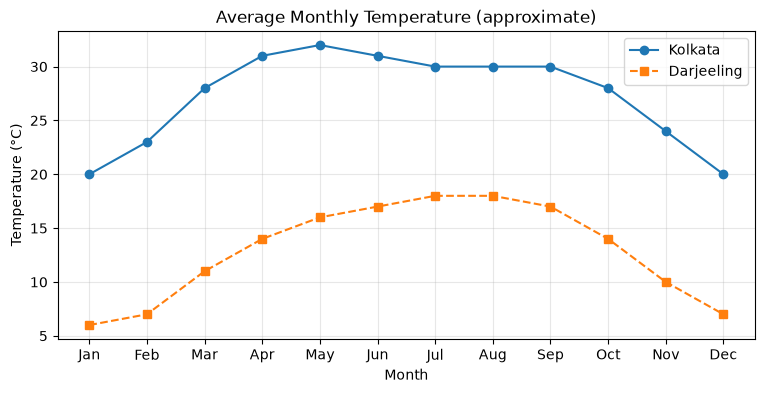

In [3]:
plt.figure(figsize=(9, 4))
plt.plot(months, kolkata, marker="o", label="Kolkata")
plt.plot(months, darjeeling, marker="s", linestyle="--", label="Darjeeling")
plt.title("Average Monthly Temperature (approximate)")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

| Function | What it adds |
|---|---|
| `plt.figure(figsize=(w, h))` | Size of the chart |
| `plt.title()` | Title |
| `plt.xlabel()`, `plt.ylabel()` | Axis labels |
| `plt.legend()` | Box that names each line |
| `plt.grid()` | Background grid lines |

## **Bar Chart**
A **bar chart** **compares** values between categories.

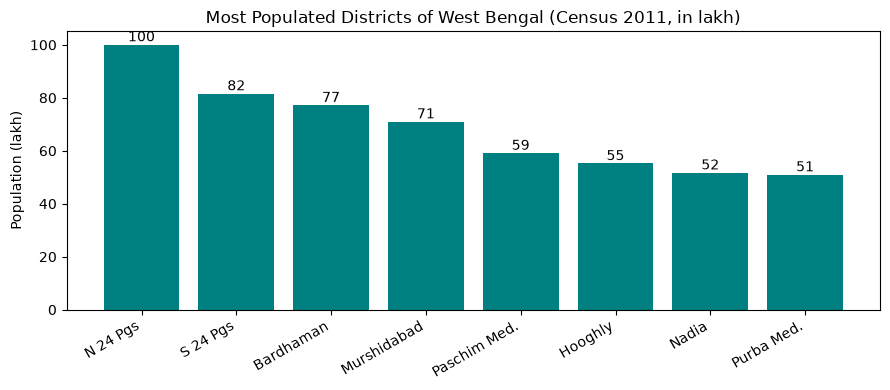

In [4]:
districts = ["N 24 Pgs", "S 24 Pgs", "Bardhaman", "Murshidabad", "Paschim Med.", "Hooghly", "Nadia", "Purba Med."]
pop_lakh = [100.1, 81.6, 77.2, 71.0, 59.1, 55.2, 51.7, 51.0]

plt.figure(figsize=(9, 4))
bars = plt.bar(districts, pop_lakh, color="teal")
plt.bar_label(bars, fmt="%.0f")
plt.title("Most Populated Districts of West Bengal (Census 2011, in lakh)")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Population (lakh)")
plt.tight_layout()
plt.show()

## **Scatter Plot**
A **scatter plot** shows the **relationship** between two numbers.

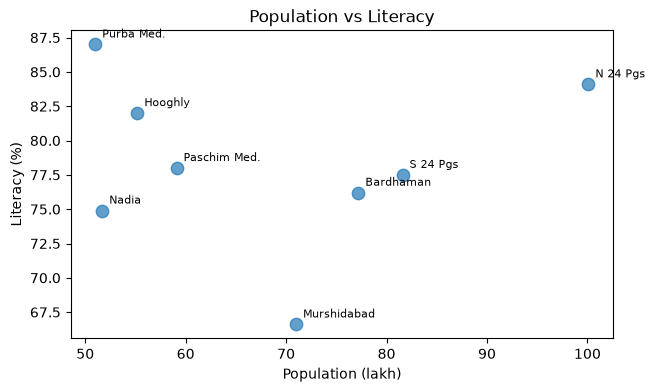

In [5]:
literacy = [84.1, 77.5, 76.2, 66.6, 78.0, 82.0, 74.9, 87.0]

plt.figure(figsize=(7, 4))
plt.scatter(pop_lakh, literacy, s=80, alpha=0.7)
for name, x, y in zip(districts, pop_lakh, literacy):
    plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)
plt.xlabel("Population (lakh)")
plt.ylabel("Literacy (%)")
plt.title("Population vs Literacy")
plt.show()

## **Example from Remote Sensing: Spectral Signature Chart**
A **spectral signature** shows how much light a material reflects at each wavelength. It is like a **fingerprint**: water, plants and soil each have their own shape. This is the most important chart in Remote Sensing.

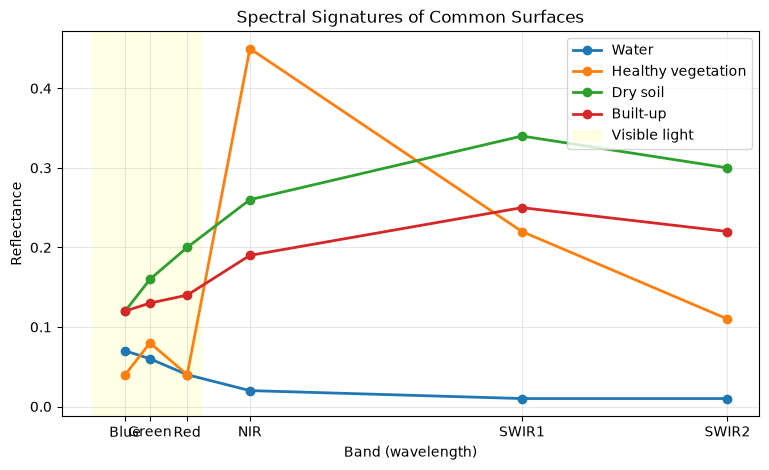

In [6]:
wavelength = [490, 560, 665, 842, 1610, 2190]          # Sentinel-2 bands in nm
band_names = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]

signatures = {
    "Water": [0.07, 0.06, 0.04, 0.02, 0.01, 0.01],
    "Healthy vegetation": [0.04, 0.08, 0.04, 0.45, 0.22, 0.11],
    "Dry soil": [0.12, 0.16, 0.20, 0.26, 0.34, 0.30],
    "Built-up": [0.12, 0.13, 0.14, 0.19, 0.25, 0.22],
}

plt.figure(figsize=(9, 5))
for name, values in signatures.items():
    plt.plot(wavelength, values, marker="o", linewidth=2, label=name)
plt.axvspan(400, 700, color="yellow", alpha=0.1, label="Visible light")
plt.xticks(wavelength, band_names)
plt.xlabel("Band (wavelength)")
plt.ylabel("Reflectance")
plt.title("Spectral Signatures of Common Surfaces")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Let us read the chart:
- **Vegetation** has a sudden big jump from Red to NIR. This jump is called the **red edge**, and it is why NDVI works so well.
- **Water** reflects almost nothing in NIR and SWIR, so it looks very dark in those bands.
- **Soil** and **built-up** areas rise slowly and steadily.

## **Pie Chart**

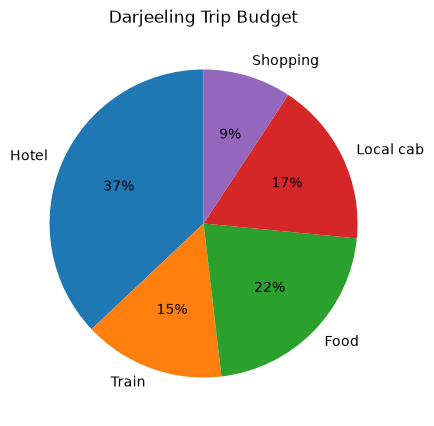

In [7]:
budget = {"Hotel": 6000, "Train": 2400, "Food": 3500, "Local cab": 2800, "Shopping": 1500}

plt.figure(figsize=(5, 5))
plt.pie(budget.values(), labels=budget.keys(), autopct="%1.0f%%", startangle=90)
plt.title("Darjeeling Trip Budget")
plt.show()

## **Histogram**
A **histogram** shows how values are **spread out**. It is used a lot to look at the pixel values of a satellite band.

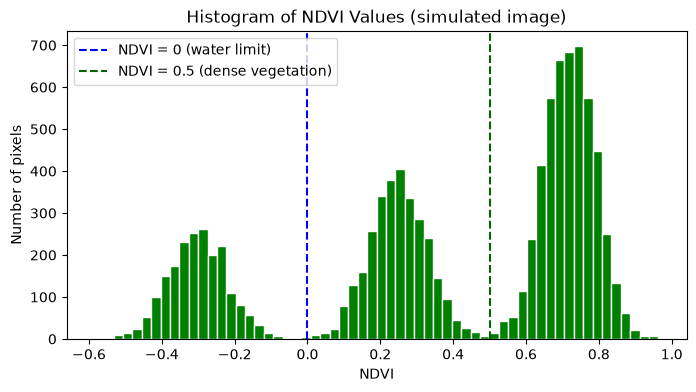

In [8]:
rng = np.random.default_rng(1)
ndvi_pixels = np.concatenate([rng.normal(-0.3, 0.08, 2000),      # Water
                              rng.normal(0.25, 0.08, 3000),      # Crops / soil
                              rng.normal(0.72, 0.07, 5000)])     # Forest

plt.figure(figsize=(8, 4))
plt.hist(ndvi_pixels, bins=60, color="green", edgecolor="white")
plt.axvline(0, color="blue", linestyle="--", label="NDVI = 0 (water limit)")
plt.axvline(0.5, color="darkgreen", linestyle="--", label="NDVI = 0.5 (dense vegetation)")
plt.xlabel("NDVI")
plt.ylabel("Number of pixels")
plt.title("Histogram of NDVI Values (simulated image)")
plt.legend()
plt.show()

The histogram has **three peaks**, one for each land cover type. Looking at a histogram like this helps us choose good **threshold values** for classification.

## **Saving a Chart as an Image**

In [9]:
plt.figure(figsize=(6, 3))
plt.plot(months, kolkata, color="orange")
plt.title("Kolkata Temperature")
plt.savefig("kolkata_temperature.png", dpi=150, bbox_inches="tight")
plt.close()

import os
print("Saved:", os.path.exists("kolkata_temperature.png"))

Saved: True


In [10]:
# Quick question
# Which chart type is best to compare the population of 5 districts?